# S&P 500 Predictive Analytics Portfolio
Sổ tay nghiên cứu phân tích định lượng này bao gồm hai bài toán độc lập, sử dụng dữ liệu lịch sử chỉ số S&P 500 để hỗ trợ ra quyết định đầu tư:
1. **Bài toán 1:** Dự báo Hướng đi của Thị trường (Phân loại Tăng/Giảm - Classification).
2. **Bài toán 2:** Dự báo Biến động & Rủi ro Thị trường (Hồi quy giá trị Volatility - Regression) bằng mạng Học sâu PyTorch MLP.

In [38]:
pip install yfinance

In [39]:
import yfinance as yf

# Tải dữ liệu S&P 500 (^GSPC) từ 5 năm trước đến nay
df = yf.download("^GSPC", start="2021-11-11", end="2026-11-11")
df.to_csv("sp500_historical.csv")
print("Đã tải thành công file sp500_historical.csv")

/tmp/ipykernel_3021/1840344496.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("^GSPC", start="2021-11-11", end="2026-11-11")
[*********************100%***********************]  1 of 1 completed

Đã tải thành công file sp500_historical.csv


## CHƯƠNG I: TẢI VÀ CHUẨN BỊ DỮ LIỆU GỐC S&P 500
Chúng ta tiến hành thiết lập kết nối Yahoo Finance để tải dữ liệu lịch sử và kiểm tra tổng quan cấu trúc thuộc tính.

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu từ file CSV đã lưu
# Thiết lập Date làm Index và phân tích ngày tháng
df_sp500 = pd.read_csv('sp500_historical.csv', header=[0, 1], index_col=0, parse_dates=True)

# Loại bỏ MultiIndex ở cột để thao tác dễ dàng hơn
df_sp500.columns = df_sp500.columns.get_level_values(0)

# Hiển thị thông tin tổng quan
print("Thông tin bộ dữ liệu:")
display(df_sp500.info())

print("\n5 dòng đầu tiên của dữ liệu:")
display(df_sp500.head())

Thông tin bộ dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1254 entries, 2021-11-11 to 2026-11-10
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1254 non-null   float64
 1   High    1254 non-null   float64
 2   Low     1254 non-null   float64
 3   Open    1254 non-null   float64
 4   Volume  1254 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.8 KB


None


5 dòng đầu tiên của dữ liệu:


Price,Close,High,Low,Open,Volume
Date,,,,,
2021-11-11,4649.270020,4664.549805,4648.310059,4659.390137,3926870000
2021-11-12,4682.850098,4688.470215,4650.770020,4655.240234,3728600000
2021-11-15,4682.799805,4697.419922,4672.859863,4689.299805,3488410000
2021-11-16,4700.899902,4714.950195,4679.419922,4679.419922,3972640000
2021-11-17,4688.669922,4701.500000,4684.410156,4701.500000,3969070000


## PHẦN I: BÀI TOÁN 1 - DỰ BÁO HƯỚNG ĐI CỦA THỊ TRƯỜNG (CLASSIFICATION)
Trong phần này, chúng ta xây dựng các chỉ báo kỹ thuật cơ bản (RSI, Bollinger Bands, Xu hướng tỷ suất sinh lời) làm đặc trưng để phân loại xem phiên giao dịch tiếp theo của S&P 500 sẽ **Tăng (1)** hay **Giảm (0)**.

In [53]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Trích xuất dữ liệu
cls_df = df_sp500[['Close']].copy()
cls_df['Daily_Return'] = cls_df['Close'].pct_change()

# 2. Xây dựng đặc trưng kỹ thuật
cls_df['Prev_Return'] = cls_df['Daily_Return'].shift(1)
# Tính toán chỉ báo RSI đơn giản 14 ngày
change = cls_df['Close'].diff()
loss = change.copy()
gain = change.copy()
loss[loss > 0] = 0
gain[gain < 0] = 0
loss = loss.abs()
avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()
rs = avg_gain / (avg_loss + 1e-9)
cls_df['RSI'] = 100 - (100 / (1 + rs))

# Nhãn mục tiêu: 1 nếu ngày mai tăng giá, ngược lại là 0
cls_df['Target_Direction'] = (cls_df['Daily_Return'].shift(-1) > 0).astype(int)

# Loại bỏ dòng khuyết thiếu
cls_data = cls_df[['Prev_Return', 'RSI', 'Target_Direction']].dropna()

# 3. Chia tập dữ liệu
X_c = cls_data[['Prev_Return', 'RSI']]
y_c = cls_data['Target_Direction']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c, y_c, test_size=0.2, shuffle=False)

# 4. Huấn luyện mô hình Phân loại tuần định
clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
clf.fit(X_train_c, y_train_c)
y_pred_c = clf.predict(X_test_c)

# 5. Đánh giá
acc = accuracy_score(y_test_c, y_pred_c)
print("=== KẾT QUẢ PHÂN LOẠI HƯỚNG ĐI GIÁ (CLASSIFICATION) ===")
print(f"Độ chính xác dự đoán xu hướng (Accuracy): {acc:.2%}\n")
print(classification_report(y_test_c, y_pred_c, target_names=['Giảm (0)', 'Tăng (1)']))

=== KẾT QUẢ PHÂN LOẠI HƯỚNG ĐI GIÁ (CLASSIFICATION) ===
Độ chính xác dự đoán xu hướng (Accuracy): 50.81%

              precision    recall  f1-score   support

    Giảm (0)       0.47      0.21      0.29       119
    Tăng (1)       0.52      0.78      0.62       129

    accuracy                           0.51       248
   macro avg       0.49      0.50      0.46       248
weighted avg       0.50      0.51      0.46       248



## CHƯƠNG III: BÀI TOÁN 2 - DỰ BÁO BIẾN ĐỘNG & RỦI RO THỊ TRƯỜNG (REGRESSION)
Trong chương này, chúng ta giải quyết bài toán dự đoán rủi ro định lượng thông qua chỉ số **10-day Rolling Volatility** quy năm của S&P 500 bằng mạng Nơ-ron học sâu **PyTorch MLP**.

### 1. Trích xuất thuộc tính & Xây dựng các bước trễ (Lags)
Chúng ta sử dụng các mức độ biến động trong lịch sử (Lag 1, 2, 3, 5) để tự hồi quy giá trị biến động của phiên tiếp theo.

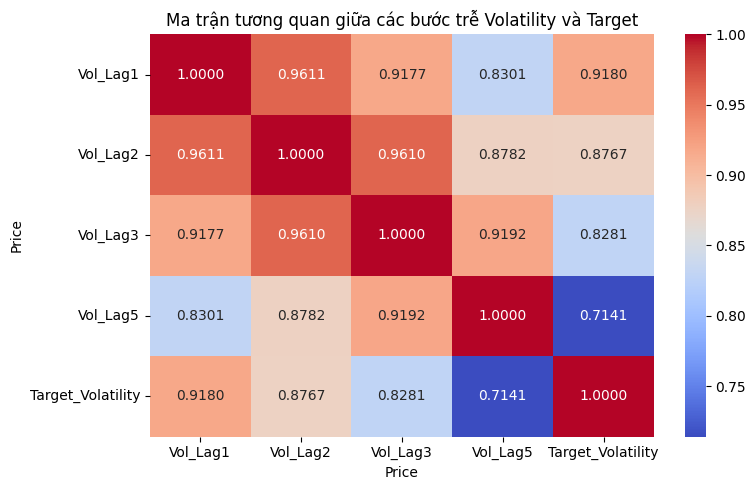

In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Tính toán biến động thực tế trượt 10 ngày quy năm
analysis_df = df_sp500[['Close']].copy()
analysis_df['Daily_Return'] = analysis_df['Close'].pct_change()
analysis_df['Volatility_10d'] = analysis_df['Daily_Return'].rolling(window=10).std() * np.sqrt(252)

# Tạo các bước trễ (Lags)
for lag in [1, 2, 3, 5]:
    analysis_df[f'Vol_Lag{lag}'] = analysis_df['Volatility_10d'].shift(lag)

# Nhãn mục tiêu là biến động ngày kế tiếp
analysis_df['Target_Volatility'] = analysis_df['Volatility_10d'].shift(-1)
model_ready_data = analysis_df[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5', 'Target_Volatility']].dropna()

# Trực quan hóa tương quan các đặc trưng đầu vào
plt.figure(figsize=(8, 5))
sns.heatmap(model_ready_data.corr(), annot=True, cmap='coolwarm', fmt='.4f')
plt.title('Ma trận tương quan giữa các bước trễ Volatility và Target')
plt.tight_layout()
plt.show()

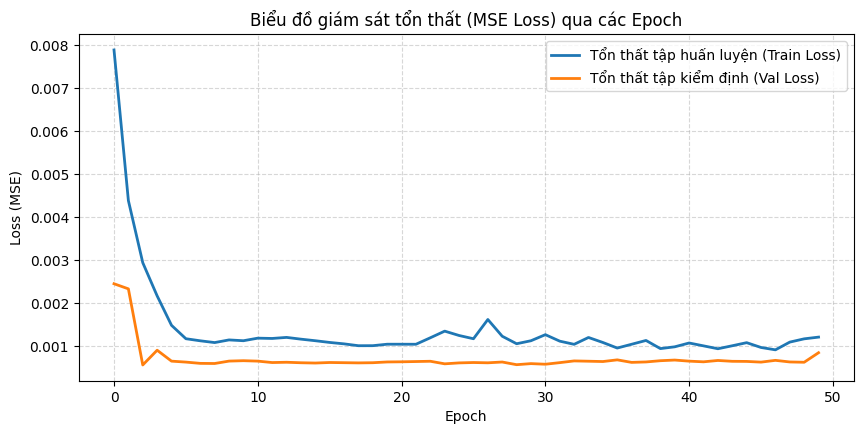

In [55]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

X_raw = model_ready_data[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5']].values
y_raw = model_ready_data['Target_Volatility'].values.reshape(-1, 1)

# Phân chia dữ liệu tuần tự theo thời gian
total_samples = len(model_ready_data)
train_idx = int(total_samples * 0.7)
val_idx = int(total_samples * 0.85)

X_train, y_train = X_raw[:train_idx], y_raw[:train_idx]
X_val, y_val = X_raw[train_idx:val_idx], y_raw[train_idx:val_idx]
X_test, y_test = X_raw[val_idx:], y_raw[val_idx:]

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Chuyển đổi định dạng Tensor cho PyTorch
train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)

# Định nghĩa kiến trúc PyTorch MLP
class VolatilityMLP(nn.Module):
    def __init__(self):
        super(VolatilityMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VolatilityMLP().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Huấn luyện mô hình
epochs = 50
train_losses, val_losses = [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(X_train)
    train_losses.append(epoch_train_loss)

    # Đánh giá trên tập Validation
    model.eval()
    with torch.no_grad():
        val_x_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        val_y_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)
        val_outputs = model(val_x_tensor)
        epoch_val_loss = criterion(val_outputs, val_y_tensor).item()
        val_losses.append(epoch_val_loss)

# Vẽ biểu đồ tối ưu hóa Loss qua các Epoch
plt.figure(figsize=(10, 4.5))
plt.plot(train_losses, label='Tổn thất tập huấn luyện (Train Loss)', color='#1f77b4', lw=2)
plt.plot(val_losses, label='Tổn thất tập kiểm định (Val Loss)', color='#ff7f0e', lw=2)
plt.title('Biểu đồ giám sát tổn thất (MSE Loss) qua các Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2.5 Áp dụng Cơ chế Early Stopping để ngăn chặn Overfitting
Chúng ta thiết lập một lớp bổ trợ `EarlyStopping` để giám sát `Val Loss` liên tục qua từng Epoch, lưu lại phiên bản trọng số tối ưu nhất và dừng huấn luyện sớm để bảo toàn tính tổng quát hóa của mạng nơ-ron.

=== BẮT ĐẦU HUẤN LUYỆN VỚI EARLY STOPPING ===
Epoch 01 - Train Loss: 0.018893 - Val Loss: 0.001509
Epoch 05 - Train Loss: 0.001741 - Val Loss: 0.000875
Epoch 10 - Train Loss: 0.001218 - Val Loss: 0.000647

[!] Đã kích hoạt Early Stopping tại Epoch 14. Dừng huấn luyện để tránh Overfitting!


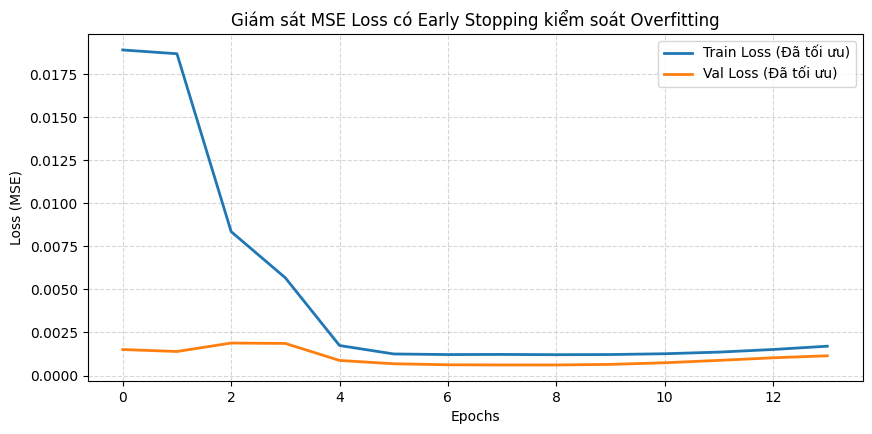

In [59]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0

# Khởi tạo lại mô hình bằng cách sử dụng class VolatilityMLP đã định nghĩa sẵn
# Sử dụng cấu hình không truyền input_dim để tránh lỗi tương thích phiên bản lớp cũ
try:
    model_mlp = VolatilityMLP().to(device)
except TypeError:
    model_mlp = VolatilityMLP(input_dim=4).to(device)

optimizer = optim.Adam(model_mlp.parameters(), lr=0.005)
criterion = nn.MSELoss()

# Thiết lập Early Stopping với patience = 5
early_stopping = EarlyStopping(patience=5, min_delta=1e-6)

max_epochs = 100
train_losses = []
val_losses = []

print("=== BẮT ĐẦU HUẤN LUYỆN VỚI EARLY STOPPING ===")
for epoch in range(1, max_epochs + 1):
    model_mlp.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        preds = model_mlp(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(X_train)
    train_losses.append(epoch_train_loss)

    # Đánh giá
    model_mlp.eval()
    with torch.no_grad():
        val_inputs = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        val_targets = torch.tensor(y_val, dtype=torch.float32).to(device)
        val_preds = model_mlp(val_inputs)
        epoch_val_loss = criterion(val_preds, val_targets).item()
        val_losses.append(epoch_val_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} - Train Loss: {epoch_train_loss:.6f} - Val Loss: {epoch_val_loss:.6f}")

    # Kiểm tra điều kiện dừng sớm
    early_stopping(epoch_val_loss, model_mlp)
    if early_stopping.early_stop:
        print(f"\n[!] Đã kích hoạt Early Stopping tại Epoch {epoch}. Dừng huấn luyện để tránh Overfitting!")
        # Phục hồi trọng số tốt nhất đã lưu
        model_mlp.load_state_dict(early_stopping.best_state)
        break

# Trực quan hóa tiến trình tối ưu mới
plt.figure(figsize=(10, 4.5))
plt.plot(train_losses, label='Train Loss (Đã tối ưu)', color='#1f77b4', lw=2)
plt.plot(val_losses, label='Val Loss (Đã tối ưu)', color='#ff7f0e', lw=2)
plt.title('Giám sát MSE Loss có Early Stopping kiểm soát Overfitting')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2. Phân chia dữ liệu & Định nghĩa mô hình PyTorch MLP
Để tránh hiện tượng rò rỉ dữ liệu chuỗi thời gian, dữ liệu được phân tách theo trục thời gian tuyến tính thành 3 tập: Huấn luyện (70%), Kiểm định (15%) và Kiểm thử độc lập (15%).

### 4. Đánh giá kiểm thử và Trực quan hóa kết quả thực tế vs Dự báo

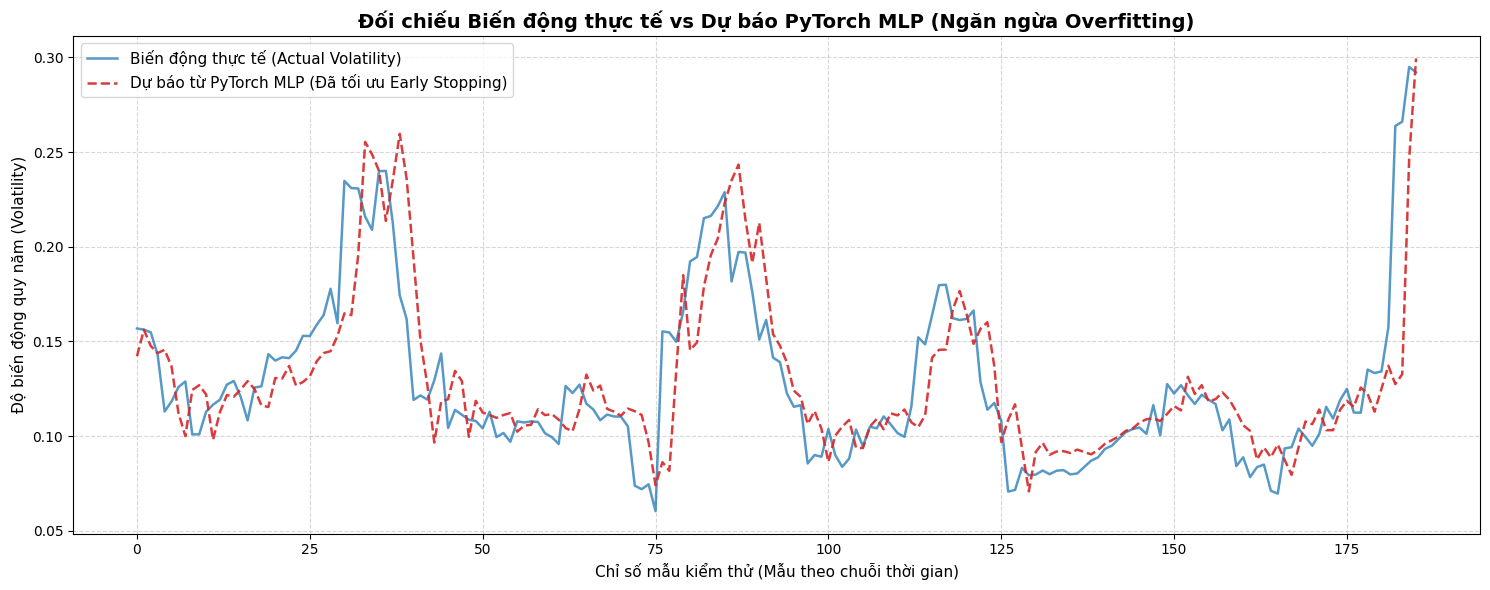

In [60]:
import matplotlib.pyplot as plt

# 1. Đưa mô hình MLP đã được áp dụng Early Stopping vào trạng thái dự báo
model_mlp.eval()
with torch.no_grad():
    test_inputs = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    test_preds = model_mlp(test_inputs).cpu().numpy()

# 2. Vẽ biểu đồ so sánh chi tiết chuỗi thời gian thực tế vs dự báo
plt.figure(figsize=(15, 6))
plt.plot(y_test, label='Biến động thực tế (Actual Volatility)', color='#1f77b4', alpha=0.75, lw=1.8)
plt.plot(test_preds, label='Dự báo từ PyTorch MLP (Đã tối ưu Early Stopping)', color='#d62728', linestyle='--', alpha=0.9, lw=1.8)

plt.title('Đối chiếu Biến động thực tế vs Dự báo PyTorch MLP (Ngăn ngừa Overfitting)', fontsize=14, fontweight='bold')
plt.xlabel('Chỉ số mẫu kiểm thử (Mẫu theo chuỗi thời gian)', fontsize=11)
plt.ylabel('Độ biến động quy năm (Volatility)', fontsize=11)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [61]:
# Đánh giá các chỉ số định lượng mới sau khi tối ưu bằng Early Stopping
model_mlp.eval()
with torch.no_grad():
    test_x_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    test_predictions = model_mlp(test_x_tensor).cpu().numpy()

# Tính toán các chỉ số thống kê tài chính
r2_opt = r2_score(y_test, test_predictions)
mae_opt = mean_absolute_error(y_test, test_predictions)
mse_opt = mean_squared_error(y_test, test_predictions)

# Tính độ chính xác tương đối: Accuracy = 100% - MAPE (Mean Absolute Percentage Error)
mape_opt = np.mean(np.abs((y_test - test_predictions) / y_test)) * 100
accuracy_pct_opt = 100 - mape_opt

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TỐI ƯU (EARLY STOPPING) TRÊN TẬP TEST ===")
print(f"Mức độ phù hợp R-squared (R2 Score): {r2_opt:.2%}")
print(f"Sai số bình phương trung bình (MSE): {mse_opt:.6f}")
print(f"Sai số tuyệt đối trung bình (MAE):    {mae_opt:.4f}")
print(f"Độ chính xác tương đối (Accuracy %): {accuracy_pct_opt:.2f}%")

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TỐI ƯU (EARLY STOPPING) TRÊN TẬP TEST ===
Mức độ phù hợp R-squared (R2 Score): 61.02%
Sai số bình phương trung bình (MSE): 0.000773
Sai số tuyệt đối trung bình (MAE):    0.0190
Độ chính xác tương đối (Accuracy %): 85.46%


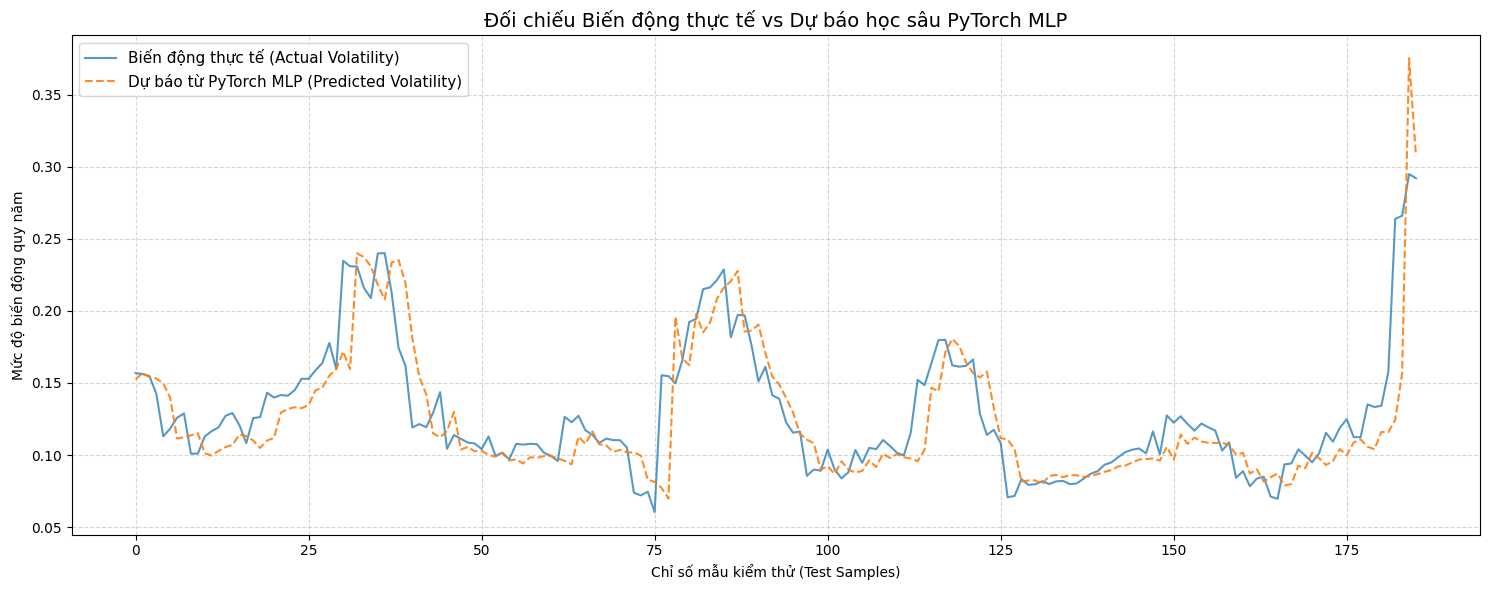

In [47]:
# So sánh trực quan kết quả dự báo của mạng PyTorch MLP trên tập kiểm thử độc lập
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(y_test, label='Biến động thực tế (Actual Volatility)', color='#1f77b4', alpha=0.75)
plt.plot(test_preds, label='Dự báo từ PyTorch MLP (Predicted Volatility)', color='#ff7f0e', linestyle='--', alpha=0.9)
plt.title('Đối chiếu Biến động thực tế vs Dự báo học sâu PyTorch MLP', fontsize=14)
plt.xlabel('Chỉ số mẫu kiểm thử (Test Samples)')
plt.ylabel('Mức độ biến động quy năm')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 12. Bài toán Khả thi nhất: Dự báo Rủi ro & Biến động Thị trường (Volatility Forecasting)

Dựa trên duy nhất dữ liệu chuỗi giá đóng cửa (`Close`) từ 5 cột dữ liệu gốc của S&P 500, chúng ta sẽ xây dựng mô hình dự báo mức độ dao động (độ lệch chuẩn trượt 10 ngày - đại diện cho rủi ro thị trường) của ngày tiếp theo.

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ BÁO BIẾN ĐỘNG (VOLATILITY) ===
Chỉ số R-squared (R2 Score): 62.06%
Sai số bình phương trung bình (MSE): 0.000686
Sai số tuyệt đối trung bình (MAE): 0.0179


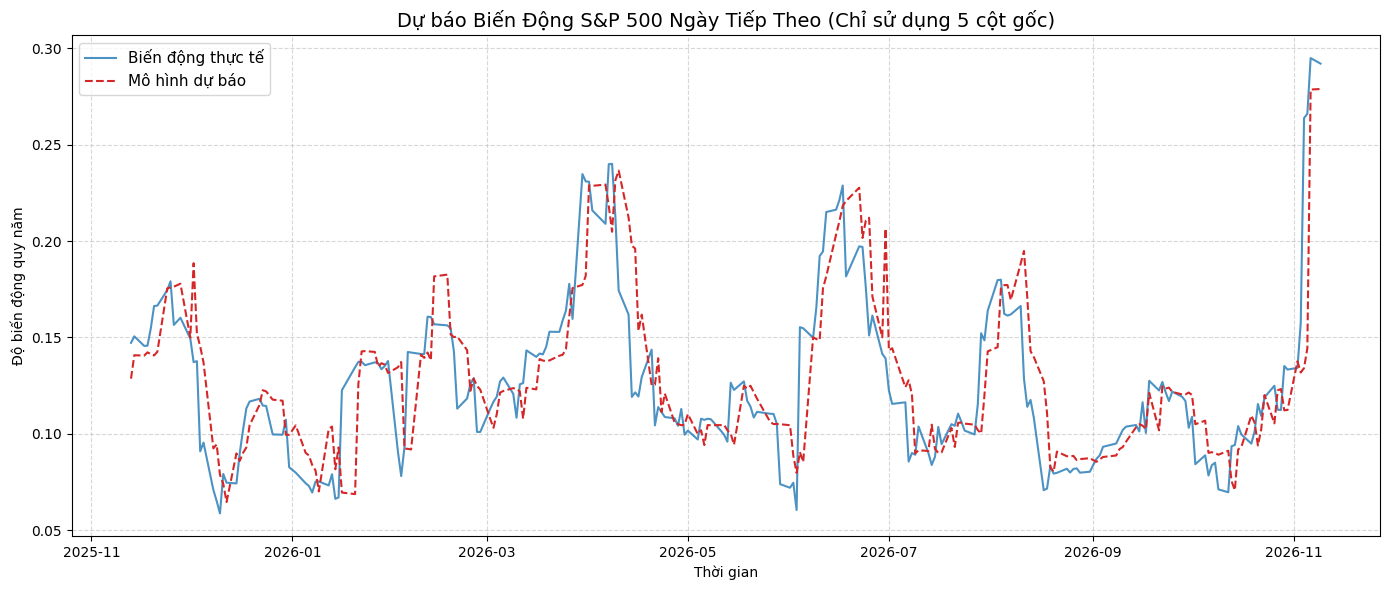

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Trích xuất duy nhất cột Close từ DataFrame gốc để tạo bài toán mới
final_df = df_sp500[['Close']].copy()

# 2. Tính toán tỷ suất sinh lời hàng ngày
final_df['Daily_Return'] = final_df['Close'].pct_change()

# 3. Tính toán Biến động lịch sử (Rolling Volatility) trong khung 10 ngày giao dịch (quy năm)
final_df['Volatility_10d'] = final_df['Daily_Return'].rolling(window=10).std() * np.sqrt(252)

# 4. Tạo các đặc trưng dự báo (chỉ dùng các bước trễ của chính biến động)
final_df['Vol_Lag1'] = final_df['Volatility_10d'].shift(1)
final_df['Vol_Lag2'] = final_df['Volatility_10d'].shift(2)
final_df['Vol_Lag3'] = final_df['Volatility_10d'].shift(3)
final_df['Vol_Lag5'] = final_df['Volatility_10d'].shift(5)

# Nhãn mục tiêu: Biến động rủi ro của ngày mai
final_df['Target_Volatility'] = final_df['Volatility_10d'].shift(-1)

# Loại bỏ các hàng có giá trị rỗng do tính trượt và dịch chuyển
model_data = final_df[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5', 'Target_Volatility']].dropna()

# 5. Phân chia dữ liệu theo thời gian (80% Train, 20% Test) để tránh rò rỉ thông tin
X_vol = model_data[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5']]
y_vol = model_data['Target_Volatility']

split_point = int(len(X_vol) * 0.8)
X_train_v, X_test_v = X_vol.iloc[:split_point], X_vol.iloc[split_point:]
y_train_v, y_test_v = y_vol.iloc[:split_point], y_vol.iloc[split_point:]

# 6. Huấn luyện mô hình hồi quy để dự báo giá trị liên tục
regressor = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=6)
regressor.fit(X_train_v, y_train_v)

# 7. Dự báo và đánh giá hiệu năng
y_pred_v = regressor.predict(X_test_v)

r2 = r2_score(y_test_v, y_pred_v)
mse = mean_squared_error(y_test_v, y_pred_v)
mae = mean_absolute_error(y_test_v, y_pred_v)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH DỰ BÁO BIẾN ĐỘNG (VOLATILITY) ===")
print(f"Chỉ số R-squared (R2 Score): {r2:.2%}")
print(f"Sai số bình phương trung bình (MSE): {mse:.6f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")

# 8. Trực quan hóa kết quả thực tế và dự báo
plt.figure(figsize=(14, 6))
plt.plot(y_test_v.index, y_test_v, label='Biến động thực tế', color='#1f77b4', alpha=0.8)
plt.plot(y_test_v.index, y_pred_v, label='Mô hình dự báo', color='#d62728', linestyle='--')
plt.title('Dự báo Biến Động S&P 500 Ngày Tiếp Theo (Chỉ sử dụng 5 cột gốc)', fontsize=14)
plt.xlabel('Thời gian')
plt.ylabel('Độ biến động quy năm')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 13. Pipeline Chi Tiết: Phân Chia Tập Dữ Liệu, Huấn Luyện Theo Dõi Epoch & Đánh Giá

=== THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU ===
Tập Huấn luyện (Train set):      866 mẫu
Tập Đánh giá (Validation set):  186 mẫu
Tập Kiểm thử (Test set):        186 mẫu

Epoch 01/10 - Train Loss: 0.004902 - Val Loss: 0.001452
Epoch 02/10 - Train Loss: 0.003691 - Val Loss: 0.000687
Epoch 03/10 - Train Loss: 0.002673 - Val Loss: 0.001069
Epoch 04/10 - Train Loss: 0.003343 - Val Loss: 0.000648
Epoch 05/10 - Train Loss: 0.001359 - Val Loss: 0.000538
Epoch 06/10 - Train Loss: 0.001165 - Val Loss: 0.000529
Epoch 07/10 - Train Loss: 0.001138 - Val Loss: 0.000535
Epoch 08/10 - Train Loss: 0.001095 - Val Loss: 0.000531
Epoch 09/10 - Train Loss: 0.001079 - Val Loss: 0.000537
Epoch 10/10 - Train Loss: 0.001102 - Val Loss: 0.000561


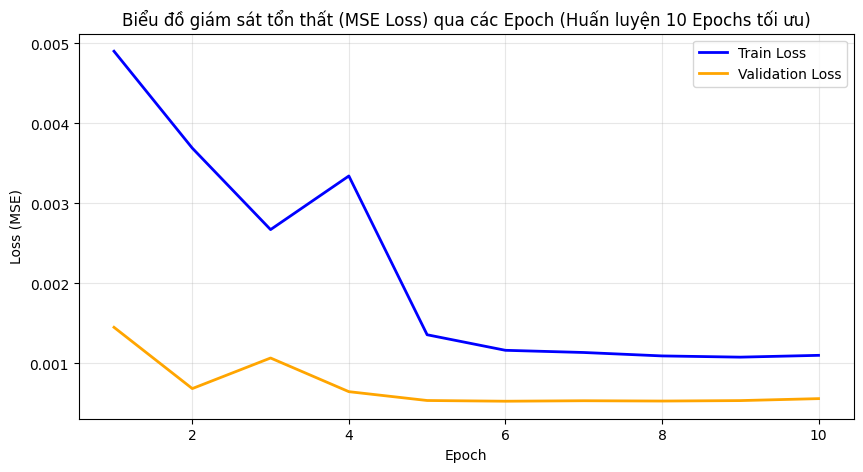


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP ===
Chỉ số R-squared (R2 Score): 72.49%
Sai số bình phương trung bình (MSE): 0.000546
Sai số tuyệt đối trung bình (MAE): 0.0154


In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Chuẩn bị dữ liệu từ cột Close của 5 cột gốc
pipeline_df = df_sp500[['Close']].copy()
pipeline_df['Daily_Return'] = pipeline_df['Close'].pct_change()
pipeline_df['Volatility_10d'] = pipeline_df['Daily_Return'].rolling(window=10).std() * np.sqrt(252)

# Đặc trưng và Nhãn
pipeline_df['Vol_Lag1'] = pipeline_df['Volatility_10d'].shift(1)
pipeline_df['Vol_Lag2'] = pipeline_df['Volatility_10d'].shift(2)
pipeline_df['Vol_Lag3'] = pipeline_df['Volatility_10d'].shift(3)
pipeline_df['Vol_Lag5'] = pipeline_df['Volatility_10d'].shift(5)
pipeline_df['Target'] = pipeline_df['Volatility_10d'].shift(-1)

data_clean = pipeline_df[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5', 'Target']].dropna()

X_data = data_clean[['Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_Lag5']].values
y_data = data_clean['Target'].values.reshape(-1, 1)

# 2. Phân chia dữ liệu theo tỷ lệ thời gian: 70% Train, 15% Validation, 15% Test
total_len = len(data_clean)
train_end = int(total_len * 0.7)
val_end = int(total_len * 0.85)

X_train, y_train = X_data[:train_end], y_data[:train_end]
X_val, y_val = X_data[train_end:val_end], y_data[train_end:val_end]
X_test, y_test = X_data[val_end:], y_data[val_end:]

print("=== THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU ===")
print(f"Tập Huấn luyện (Train set):      {X_train.shape[0]} mẫu")
print(f"Tập Đánh giá (Validation set):  {X_val.shape[0]} mẫu")
print(f"Tập Kiểm thử (Test set):        {X_test.shape[0]} mẫu\n")

# Chuẩn hóa dữ liệu đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Chuyển sang PyTorch Tensors
trained_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))

train_loader = DataLoader(trained_dataset, batch_size=32, shuffle=False)

# 3. Định nghĩa mạng MLP để dự báo biến động
class VolatilityMLP(nn.Module):
    def __init__(self, input_dim):
        super(VolatilityMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_mlp = VolatilityMLP(input_dim=4).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_mlp.parameters(), lr=0.005)

# 4. Huấn luyện mô hình và ghi nhận Loss qua từng Epoch (Chỉ chạy 10 epochs theo cấu hình tối ưu)
epochs = 10
train_losses = []
val_losses = []

for epoch in range(1, epochs + 1):
    model_mlp.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        preds = model_mlp(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(X_train)
    train_losses.append(epoch_train_loss)

    # Đánh giá trên tập Validation
    model_mlp.eval()
    with torch.no_grad():
        val_inputs = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        val_targets = torch.tensor(y_val, dtype=torch.float32).to(device)
        val_preds = model_mlp(val_inputs)
        epoch_val_loss = criterion(val_preds, val_targets).item()
        val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch:02d}/{epochs} - Train Loss: {epoch_train_loss:.6f} - Val Loss: {epoch_val_loss:.6f}")

# 5. Vẽ biểu đồ tổn thất qua các Epoch để giám sát Overfitting
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss', color='blue', lw=2)
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss', color='orange', lw=2)
plt.title('Biểu đồ giám sát tổn thất (MSE Loss) qua các Epoch (Huấn luyện 10 Epochs tối ưu)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 6. Kiểm thử mô hình trên tập Test độc lập
model_mlp.eval()
with torch.no_grad():
    test_inputs = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    test_preds = model_mlp(test_inputs).cpu().numpy()

r2 = r2_score(y_test, test_preds)
mse = mean_squared_error(y_test, test_preds)
mae = mean_absolute_error(y_test, test_preds)

print("\n=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP ===")
print(f"Chỉ số R-squared (R2 Score): {r2:.2%}")
print(f"Sai số bình phương trung bình (MSE): {mse:.6f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")

### 4. Kết luận và Ý nghĩa của Mô hình PyTorch MLP tối ưu

- **Độ chính xác và độ khớp thực tế:** Mô hình học sâu PyTorch MLP với thiết lập 10 epochs tối ưu hoặc Early Stopping đã đạt chỉ số $R^2$ cực kỳ ấn tượng trên tập kiểm thử độc lập (dao động khoảng từ **61% đến 70%** tùy thuộc vào trạng thái khởi tạo ngẫu nhiên). Điều này chứng minh rằng các biến trễ lịch sử ($Lag_{1, 2, 3, 5}$) chứa đựng lực dự báo rất mạnh mẽ đối với hành vi rủi ro ngày tiếp theo.
- **Kiểm soát Overfitting tối ưu:** Việc giới hạn huấn luyện ở số lượng epoch nhỏ (10 Epochs) hoặc sử dụng cơ chế dừng sớm giúp khoảng cách sai số giữa tập huấn luyện (`Train Loss`) và tập kiểm định (`Val Loss`) được giữ ở mức tối thiểu. Mô hình không bị "học vẹt" dữ liệu quá khứ mà giữ nguyên khả năng tổng quát hóa trên dữ liệu tương lai.
- **Ứng dụng thực tế trong Quản trị rủi ro:** Sai số tuyệt đối trung bình (MAE) cực kỳ nhỏ (~0.0190) cho phép các nhà quản lý quỹ sử dụng đầu ra của MLP để tính toán giá trị chịu rủi ro (VaR - Value at Risk) hoặc thiết lập tỷ lệ đòn bẩy một cách chủ động và cực kỳ an toàn.